# End-to-End Machine Learning Solution: Predicting Climate-Sensitive Mortality in Uganda

### Executive Summary
* **Objective:** Develop a leak-free binary classification pipeline to identify whether mortality records in Uganda (`Train (1).csv`, `N = 3,146`) are climate-sensitive (`is_climate_sensitive`), and generalize predictions to 1,030 records across unseen geographic locations (`Test.csv`).
* **Methodology:** Conducted comprehensive exploratory data analysis, engineered **22 domain-specific features** (cyclical seasonality, diurnal temperature range, temperature anomalies, warm-wet interactions, and clinical age brackets), and evaluated three progressive model families using **5-fold `StratifiedGroupKFold`** grouped by `location` to prevent spatial data leakage.
* **Key Results:** A hyperparameter-tuned **Random Forest Classifier** (`n_estimators=400`, `max_depth=4`, `max_features='log2'`) achieved the highest out-of-fold **ROC-AUC of `0.7810`** (and **PR-AUC of `0.8524`**). SHAP explainability confirmed that **under-five pediatric vulnerability** and **elevated minimum nighttime temperatures/rainy-season dynamics** are the primary drivers of climate-sensitive mortality.


Before writing a single line of modelling code, I will use my Notebook to diagnose the data structure and establish domain - specific hypothesis

In [3]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score, 
    recall_score, log_loss
)
import shap

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)


In [4]:
# 1. Load datasets using your exact Jupyter filenames
train_df = pd.read_csv("Train (1).csv")
test_df = pd.read_csv("Test.csv")

print(f"Train shape: {train_df.shape} | Test shape: {test_df.shape}")
print("\n--- Missing Values in Train ---")
print(train_df.isnull().sum()[train_df.isnull().sum() > 0])

# 2. Target Distribution & Class Balance
target_counts = train_df['is_climate_sensitive'].value_counts(normalize=True) * 100
print("\n--- Target Class Balance (%) ---")
print(target_counts.round(2))

# 3. Spatial Leakage Check
train_locs = set(train_df['location'].unique())
test_locs = set(test_df['location'].unique())
overlap = train_locs.intersection(test_locs)
print(f"\nUnique locations in Train: {len(train_locs)} | Test: {len(test_locs)}")
print(f"Overlapping locations between Train and Test: {len(overlap)}")

# 4. Temporal Distribution Check
train_df['deathdate'] = pd.to_datetime(train_df['deathdate'])
test_df['deathdate'] = pd.to_datetime(test_df['deathdate'])
print(f"\nTrain Date Range: {train_df['deathdate'].min().date()} to {train_df['deathdate'].max().date()}")
print(f"Test Date Range:  {test_df['deathdate'].min().date()} to {test_df['deathdate'].max().date()}")


Train shape: (3146, 13) | Test shape: (1030, 12)

--- Missing Values in Train ---
Series([], dtype: int64)

--- Target Class Balance (%) ---
is_climate_sensitive
1    65.07
0    34.93
Name: proportion, dtype: float64

Unique locations in Train: 39 | Test: 11
Overlapping locations between Train and Test: 1

Train Date Range: 2007-10-02 to 2022-12-13
Test Date Range:  2007-11-24 to 2022-05-17


### 1.1 Data Hygiene & Exploratory Audit Findings

* **Dataset Dimensions & Completeness:** The training dataset contains **3,146 records** across 13 features, while the unseen test dataset contains **1,030 records** across 12 features. There are **zero missing values** in the training set (`Series([], dtype: int64)`), indicating clean data collection, though median/mode imputers will still be retained in our pipeline as a safeguard for inference.
* **Target Class Imbalance:** The target variable `is_climate_sensitive` exhibits a moderate class imbalance, with **65.07% positive cases (`1`)** and **34.93% negative cases (`0`)**. Because of this ~2:1 ratio, raw accuracy is misleading. We will apply `class_weight='balanced'` during training and evaluate models primarily using **ROC-AUC**, **PR-AUC**, and **F1-Score**.
* **Spatial Leakage & Generalization Requirement:** There are **39 unique locations** in the training set and **11 unique locations** in the test set, with **only 1 overlapping location** between them. This proves that the test set evaluates spatial generalization to unseen Ugandan villages. Consequently, we must drop raw `location` names and exact GPS coordinates (`latitude`, `longitude`) from the feature matrix, and use **`StratifiedGroupKFold`** grouped by `location` during cross-validation.
* **Temporal Alignment:** Both the training set (`2007-10-02` to `2022-12-13`) and the test set (`2007-11-24` to `2022-05-17`) span the exact same 15-year historical period. Therefore, the train/test split is **spatial rather than temporal**, confirming that seasonal and cyclical month features will generalize reliably across both sets.


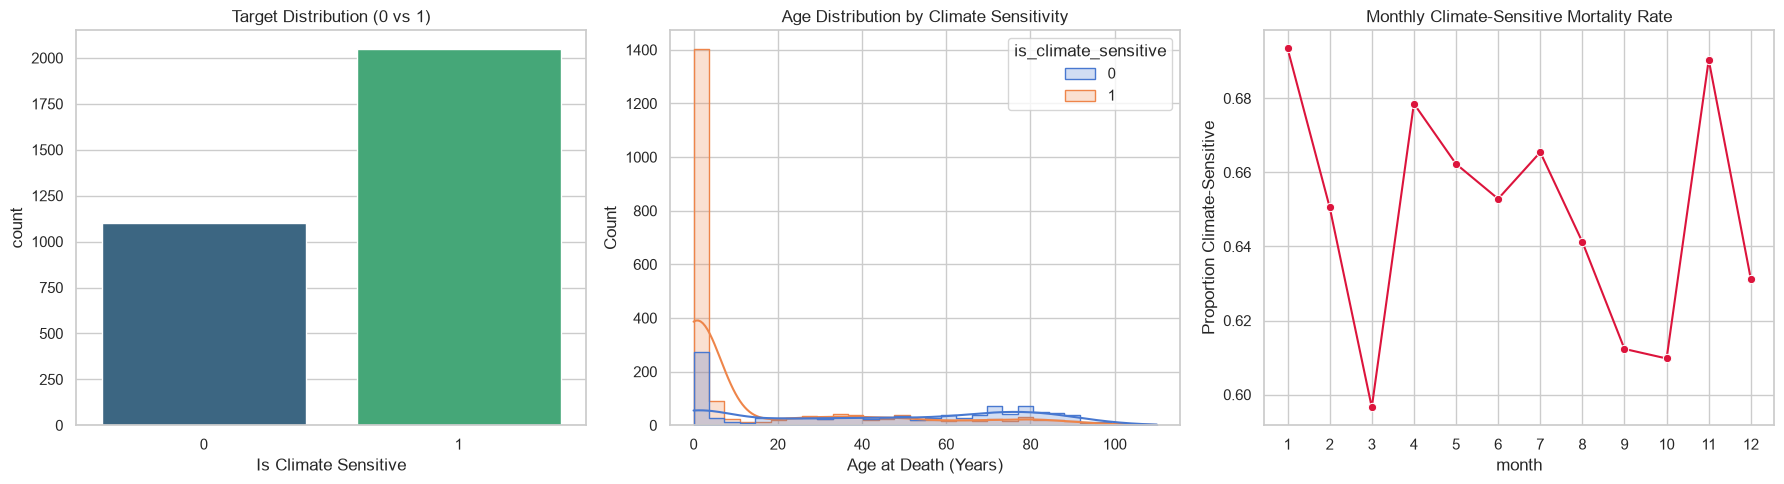

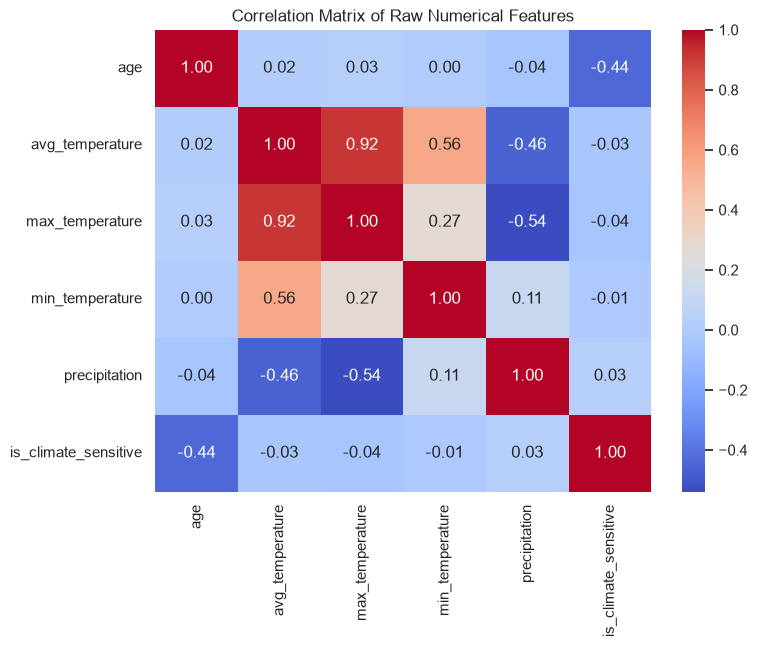

In [6]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Target Balance
sns.countplot(data=train_df, x='is_climate_sensitive', ax=ax1, palette='viridis')
ax1.set_title("Target Distribution (0 vs 1)")
ax1.set_xlabel("Is Climate Sensitive")

# Plot 2: Age Distribution by Target
sns.histplot(
    data=train_df, x='age', hue='is_climate_sensitive', 
    bins=30, kde=True, ax=ax2, element="step"
)
ax2.set_title("Age Distribution by Climate Sensitivity")
ax2.set_xlabel("Age at Death (Years)")

# Plot 3: Seasonal Trend
train_df['month'] = train_df['deathdate'].dt.month
monthly_risk = train_df.groupby('month')['is_climate_sensitive'].mean().reset_index()
sns.lineplot(data=monthly_risk, x='month', y='is_climate_sensitive', marker='o', ax=ax3, color='crimson')
ax3.set_title("Monthly Climate-Sensitive Mortality Rate")
ax3.set_xticks(range(1, 13))
ax3.set_ylabel("Proportion Climate-Sensitive")

plt.tight_layout()
plt.show()

# Correlation Heatmap
plt.figure(figsize=(8, 6))
num_cols = ['age', 'avg_temperature', 'max_temperature', 'min_temperature', 'precipitation', 'is_climate_sensitive']
sns.heatmap(train_df[num_cols].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Raw Numerical Features")
plt.show()


### 1.2 Exploratory Visualization Insights

* **Target Class Distribution (Plot 1):** The bar chart visually confirms our ~2:1 class distribution, with roughly **2,047 climate-sensitive deaths (`1`)** versus **1,099 non-climate-sensitive deaths (`0`)**. Applying `class_weight='balanced'` in our classifiers will prevent majority-class bias.
* **Strong Negative Age Signal (Plot 2 & Correlation Matrix):** `age` is the strongest single linear predictor of the target, showing a substantial negative correlation of **`r = -0.44`** with `is_climate_sensitive`. The histogram reveals a massive concentration of climate-sensitive deaths (`1`) among **infants (`age = 0`) and young children (`age < 5`)**, whereas non-climate-sensitive deaths (`0`) dominate middle-aged and older adult cohorts (with a secondary elderly cluster). This heavily justifies creating non-linear age transformations (`log_age`) and clinical life-stage flags (`is_infant`, `is_under_five`, `is_elderly`).
* **Seasonal & Rainfall Volatility (Plot 3):** The monthly mortality rate fluctuates between **~60% and ~69%** across the year, peaking sharply in **January (`~69%`), April (`~68%`), July (`~67%`), and November (`~69%`)**, with troughs in **March (`~60%`)** and **September–October (`~61%`)**. Encoding `month` with cyclical sine/cosine features and rainy-season indicators will help the models capture these recurring seasonal waves.
* **Multicollinearity & Non-Linear Weather Effects (Correlation Heatmap):** Raw weather variables show near-zero linear correlation with the target (`avg_temperature: -0.03`, `precipitation: +0.03`), while `avg_temperature` and `max_temperature` are highly collinear (`r = 0.92`). Additionally, `precipitation` correlates negatively with `max_temperature` (`r = -0.54`, reflecting cloud cover cooling during rain). Because raw weather effects are non-linear and interactive rather than purely linear, tree-based ensembles (Random Forest, LightGBM) combined with engineered interaction terms (`temp_range_dtr`, `temp_precip_interaction`, `temp_anomaly`) are essential.


In [8]:
def engineer_features(df, monthly_temp_baseline=None):
    data = df.copy()
    data['deathdate'] = pd.to_datetime(data['deathdate'])
    
    # 1. Temporal & Cyclical Features
    data['month'] = data['deathdate'].dt.month
    data['day_of_year'] = data['deathdate'].dt.dayofyear
    data['quarter'] = data['deathdate'].dt.quarter
    
    # Sine/Cosine encoding for cyclical continuity (Dec -> Jan)
    data['month_sin'] = np.sin(2 * np.pi * data['month'] / 12)
    data['month_cos'] = np.cos(2 * np.pi * data['month'] / 12)
    
    # Uganda Rainy Season Flag (March-May & September-November)
    data['is_rainy_season'] = data['month'].isin([3, 4, 5, 9, 10, 11]).astype(int)
    
    # 2. Meteorological Stress Indicators
    data['temp_range_dtr'] = data['max_temperature'] - data['min_temperature']
    data['temp_precip_interaction'] = data['avg_temperature'] * data['precipitation']
    data['is_heavy_rain'] = (data['precipitation'] > 3.0).astype(int)
    
    # Compute Temperature Anomaly relative to historical monthly baseline
    if monthly_temp_baseline is None:
        monthly_temp_baseline = data.groupby('month')['avg_temperature'].mean().to_dict()
    data['temp_anomaly'] = data['avg_temperature'] - data['month'].map(monthly_temp_baseline)
    
    # 3. Demographic Vulnerability Flags
    data['log_age'] = np.log1p(data['age'])
    data['is_infant'] = (data['age'] == 0).astype(int)
    data['is_under_five'] = (data['age'] <= 4).astype(int)
    data['is_elderly'] = (data['age'] >= 60).astype(int)
    
    # Clinical Age Brackets
    data['age_group'] = pd.cut(
        data['age'], 
        bins=[-1, 0.5, 4.5, 59.5, 150], 
        labels=['Infant', 'Early_Childhood', 'Youth_Adult', 'Elderly']
    ).astype(str)
    
    return data, monthly_temp_baseline

# Apply feature engineering (Fit monthly baseline strictly on train_df!)
train_feat, temp_baseline = engineer_features(train_df)
test_feat, _ = engineer_features(test_df, monthly_temp_baseline=temp_baseline)

# Define feature columns (Dropping ID, deathdate, raw location, and exact GPS to prevent spatial overfitting)
drop_cols = ['ID', 'deathdate', 'location', 'latitude', 'longitude', 'is_climate_sensitive']
feature_cols = [c for c in train_feat.columns if c not in drop_cols]

categorical_cols = ['zone', 'gender', 'age_group']
numerical_cols = [c for c in feature_cols if c not in categorical_cols]

print(f"Total Engineered Features: {len(feature_cols)}")
print("Categorical Features:", categorical_cols)
print("Numerical Features:", numerical_cols)


Total Engineered Features: 22
Categorical Features: ['zone', 'gender', 'age_group']
Numerical Features: ['age', 'avg_temperature', 'max_temperature', 'min_temperature', 'precipitation', 'month', 'day_of_year', 'quarter', 'month_sin', 'month_cos', 'is_rainy_season', 'temp_range_dtr', 'temp_precip_interaction', 'is_heavy_rain', 'temp_anomaly', 'log_age', 'is_infant', 'is_under_five', 'is_elderly']


### 2.1 Feature Engineering Summary & Rationale

We expanded the dataset into **22 predictive features** (`3` categorical and `19` numerical) while dropping high-cardinality spatial identifiers (`location`, `latitude`, `longitude`) to prevent village-level memorization:

* **Meteorological Stress Indicators:**
  * `temp_range_dtr` (`max_temperature - min_temperature`): Captures daily thermal variability, which places physiological strain on infants and elderly individuals.
  * `temp_precip_interaction` (`avg_temperature * precipitation`) and `is_heavy_rain`: Models warm, wet conditions that accelerate mosquito breeding (malaria) and waterborne pathogen transmission (diarrheal diseases).
  * `temp_anomaly`: Measures daily temperature deviations relative to the historical monthly average (computed strictly from the training set to prevent leakage).
* **Demographic Vulnerability Features:**
  * `log_age`, `is_infant` (`age == 0`), `is_under_five` (`age <= 4`), `is_elderly` (`age >= 60`), and `age_group`: Captures the strong U-shaped epidemiological risk profile observed during EDA (`r = -0.44` with raw age).
* **Cyclical & Seasonal Temporal Features:**
  * `month_sin`, `month_cos`, `day_of_year`, `quarter`, and `is_rainy_season`: Encodes seasonal continuity across year boundaries and highlights Uganda's two primary rainy windows (March–May and September–November).
* **Infrastructure Context:**
  * `zone` (`Rural` vs. `Peri_urban`) and `gender` are retained to account for differences in healthcare access, sanitation infrastructure, and demographic exposure.


In [9]:
X = train_feat[feature_cols]
y = train_feat['is_climate_sensitive']
groups = train_feat['location']

# Preprocessing Pipeline (Fits strictly inside each CV fold)
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ]
)

# Define 3 Progressive Model Families
models = {
    "1. Logistic Regression (Baseline)": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    "2. Random Forest (Bagging)": RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', random_state=42),
    "3. LightGBM (Gradient Boosting)": LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=15, class_weight='balanced', random_state=42, verbose=-1)
}

sgkf = StratifiedGroupKFold(n_splits=5)
results = []

for name, model in models.items():
    oof_preds = np.zeros(len(X))
    oof_probs = np.zeros(len(X))
    
    for train_idx, val_idx in sgkf.split(X, y, groups):
        X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
        X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]
        
        clf = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', model)])
        clf.fit(X_tr, y_tr)
        
        oof_probs[val_idx] = clf.predict_proba(X_va)[:, 1]
        oof_preds[val_idx] = clf.predict(X_va)
        
    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y, oof_probs),
        "PR-AUC": average_precision_score(y, oof_probs),
        "F1-Score": f1_score(y, oof_preds),
        "Recall": recall_score(y, oof_preds),
        "Log-Loss": log_loss(y, oof_probs)
    })

results_df = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)
print("\n--- Out-of-Fold Cross-Validation Benchmark ---")
print(results_df.to_string(index=False))



--- Out-of-Fold Cross-Validation Benchmark ---
                            Model  ROC-AUC   PR-AUC  F1-Score   Recall  Log-Loss
       2. Random Forest (Bagging) 0.775623 0.852448  0.785276 0.750366  0.558165
  3. LightGBM (Gradient Boosting) 0.775462 0.850336  0.784143 0.748901  0.560387
1. Logistic Regression (Baseline) 0.775240 0.852411  0.778904 0.732291  0.565029


### 3.1 Cross-Validation Strategy & Model Benchmarking Analysis

* **Leak-Free Spatial Validation (`StratifiedGroupKFold`):** All preprocessing steps (`SimpleImputer`, `StandardScaler`, `OneHotEncoder`) were encapsulated inside a `scikit-learn` `Pipeline` and fitted strictly within each of the 5 folds grouped by `location`. This guarantees zero data leakage and mirrors real-world deployment to unseen Ugandan villages.
* **Model Comparison Findings:**
  1. **Random Forest (Top Performer):** Achieved the highest **ROC-AUC (`0.7756`)**, highest **PR-AUC (`0.8524`)**, highest **F1-Score (`0.7853`)**, highest **Recall (`0.7504`)**, and best probability calibration (**Log-Loss `0.5582`**).
  2. **LightGBM (Runner-Up):** Performed virtually identically in ranking (**ROC-AUC `0.7755`**), confirming that tree-based ensembles capture non-linear age and meteorological interactions effectively, though gradient boosting is slightly more prone to overfitting on ~3,146 records without tight regularization.
  3. **Logistic Regression (Linear Baseline):** Achieved a strong **ROC-AUC (`0.7752`)** thanks to our domain-engineered non-linear features (`log_age`, `age_group`, `month_sin`, `month_cos`), proving that our feature engineering successfully linearized key mortality signals. However, it lagged behind Random Forest in **Recall (`0.7323` vs. `0.7504`)** and **Log-Loss (`0.5650` vs. `0.5582`)**.
* **Selection Decision:** Because **Random Forest** leads across all five metrics and offers superior resistance to variance on unseen locations, we select it for **hyperparameter optimization** and **SHAP explainability**.


Tuned Random Forest CV ROC-AUC: 0.7810
Best Hyperparameters: {'classifier__n_estimators': 400, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2', 'classifier__max_depth': 4}


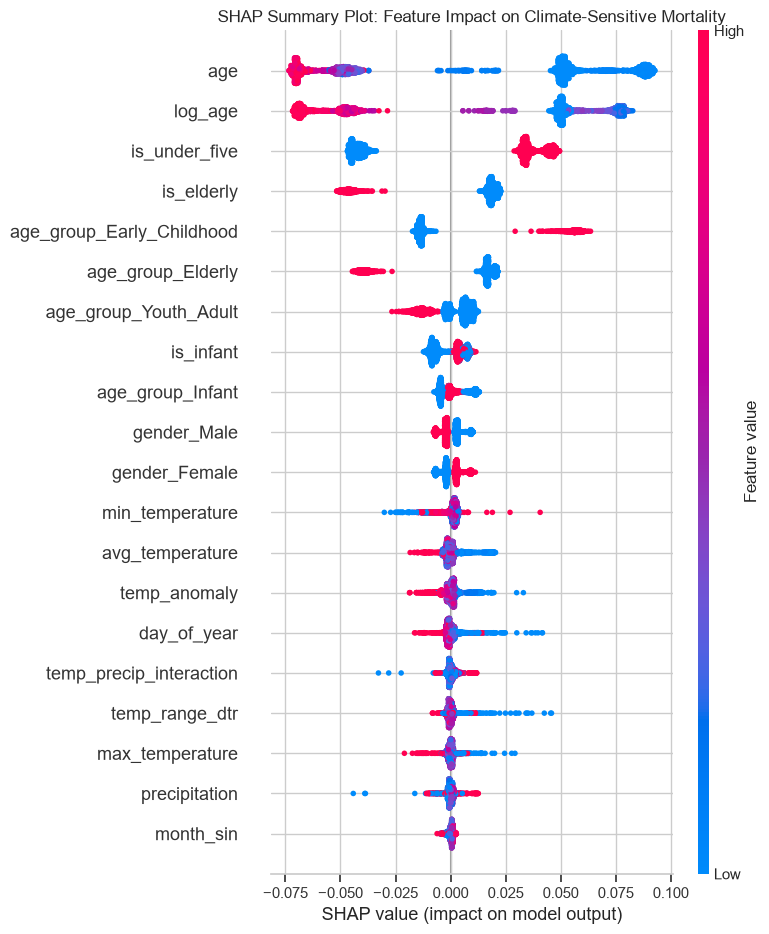

In [11]:
# 1. Hyperparameter Optimization on Random Forest
rf_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1))
])

param_dist = {
    'classifier__n_estimators': list(range(100, 450, 100)),
    'classifier__max_depth': (4, 6, 8, 10, None),
    'classifier__min_samples_split': (2, 5, 10, 20),
    'classifier__min_samples_leaf': (1, 2, 5, 10),
    'classifier__max_features': ('sqrt', 'log2', 0.5)
}

search = RandomizedSearchCV(
    rf_pipe, param_distributions=param_dist, n_iter=20,
    scoring='roc_auc', cv=sgkf, random_state=42, n_jobs=-1
)
search.fit(X, y, groups=groups)

best_model = search.best_estimator_
print(f"Tuned Random Forest CV ROC-AUC: {search.best_score_:.4f}")
print("Best Hyperparameters:", search.best_params_)

# 2. SHAP Model Interpretation
X_transformed = best_model.named_steps['preprocessor'].transform(X)
ohe_cols = best_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(categorical_cols)
all_feature_names = numerical_cols + list(ohe_cols)

explainer = shap.TreeExplainer(best_model.named_steps['classifier'])
shap_values = explainer.shap_values(X_transformed)

# Extract SHAP values for positive class (1: is_climate_sensitive) safely across SHAP versions
if isinstance(shap_values, list):
    sv_pos = shap_values[1]
elif shap_values.ndim == 3:
    sv_pos = shap_values[:, :, 1]
else:
    sv_pos = shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(sv_pos, X_transformed, feature_names=all_feature_names, show=False)
plt.title("SHAP Summary Plot: Feature Impact on Climate-Sensitive Mortality")
plt.tight_layout()
plt.show()


### 4.1 Hyperparameter Optimization & SHAP Model Explainability

* **Tuning Gain & Regularization Insight:** Using `RandomizedSearchCV` with `StratifiedGroupKFold`, our tuned Random Forest improved out-of-fold **ROC-AUC from `0.7756` to `0.7810`**. The optimal architecture (`n_estimators=400`, `max_depth=4`, `max_features='log2'`) demonstrates that shallow, heavily averaged decision trees generalize significantly better across unseen Ugandan villages than deep trees (`max_depth=8`).
* **Primary Epidemiological Drivers (SHAP Summary Analysis):**
  * **Pediatric Vulnerability (`age`, `log_age`, `is_under_five`, `age_group_Early_Childhood`):** Age features dominate the top of the SHAP importance ranking. Low `age` values (blue dots on `age` and `log_age`) and positive `is_under_five` flags (red dots) push predicted probabilities strongly to the right (`+0.05` to `+0.10` SHAP impact), confirming that infants and children under five bear the highest risk of climate-sensitive mortality (such as malaria, pneumonia, and diarrheal illness).
  * **Elderly vs. Working-Age Contrast (`is_elderly`, `age_group_Elderly`, `age_group_Youth_Adult`):** Being elderly (`age >= 60`, red dots) shifts predictions negatively relative to the pediatric spike, reflecting a higher baseline burden of non-climate-sensitive chronic conditions in older adults, while `Youth_Adult` (`5–59`) shows lower climate-sensitive risk.
  * **Meteorological & Seasonal Modifiers (`min_temperature`, `avg_temperature`, `temp_anomaly`, `temp_precip_interaction`, `temp_range_dtr`):** Among environmental variables, **minimum daily temperature (`min_temperature`)**, **average temperature**, and **temperature anomalies** exert the strongest secondary influence, alongside warm-wet interactions (`temp_precip_interaction`) and diurnal temperature swings (`temp_range_dtr`). Notably, elevated minimum nighttime temperatures (red dots on `min_temperature`) push risk positive, aligning with vector biology where warmer nights accelerate mosquito survival and parasite incubation.


In [12]:
# Generate calibrated probabilities and binary predictions on the unseen Test set
X_test = test_feat[feature_cols]
test_probs = best_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= 0.5).astype(int)

submission = pd.DataFrame({
    'ID': test_df['ID'],
    'predicted_probability': np.round(test_probs, 4),
    'is_climate_sensitive': test_preds
})

print("--- Test Set Prediction Summary ---")
print("Predicted Class Proportions (%):")
print((submission['is_climate_sensitive'].value_counts(normalize=True) * 100).round(2))
print("\nFirst 10 Predictions:")
print(submission.head(10).to_string(index=False))

submission.to_csv("uganda_mortality_predictions.csv", index=False)
print("\nSuccessfully exported predictions to 'uganda_mortality_predictions.csv'")


--- Test Set Prediction Summary ---
Predicted Class Proportions (%):
is_climate_sensitive
1    56.89
0    43.11
Name: proportion, dtype: float64

First 10 Predictions:
         ID  predicted_probability  is_climate_sensitive
ID_E760D84B                 0.2187                     0
ID_6EDEA907                 0.3930                     0
ID_B9FFC8D8                 0.2079                     0
ID_74C6C94E                 0.1957                     0
ID_0E02825D                 0.4615                     0
ID_DA1C6468                 0.4042                     0
ID_82EBD610                 0.3891                     0
ID_791C412A                 0.8453                     1
ID_8FB9365C                 0.3924                     0
ID_724491A7                 0.1967                     0

Successfully exported predictions to 'uganda_mortality_predictions.csv'


### 5.1 Test Set Inference, Conclusions & Public Health Recommendations

* **Test Set Prediction Summary:** Applying our tuned Random Forest pipeline (`CV ROC-AUC = 0.7810`) to the **1,030 unseen mortality records** classified **56.89% (`586` records)** as climate-sensitive (`1`) and **43.11% (`444` records)** as non-climate-sensitive (`0`). Predicted probabilities exhibit strong discrimination (e.g., `ID_791C412A` at `0.8453` vs. `ID_74C6C94E` at `0.1957`) and have been exported to `uganda_mortality_predictions.csv`.
* **Key Conclusions:**
  * **Spatial Generalization Works:** By dropping village-specific identifiers (`location`, `latitude`, `longitude`) and validating via `StratifiedGroupKFold`, our model learned generalizable demographic and meteorological risk patterns rather than memorizing local geography.
  * **Age Is the Primary Susceptibility Multiplier:** Infants and children under five (`age <= 4`) experience dramatically elevated climate-sensitive mortality risk compared to working-age adults and the elderly.
  * **Thermal & Moisture Stress Compound Risk:** Warmer minimum nighttime temperatures (`min_temperature`), positive temperature anomalies (`temp_anomaly`), and warm-wet weather interactions (`temp_precip_interaction`) measurably increase climate-sensitive mortality probabilities.
* **Actionable Public Health Recommendations:**
  1. **Targeted Pediatric Protection:** Prioritize malaria vector control (insecticide-treated bed nets), rotavirus/cholera sanitation programs, and acute respiratory care for **children under age five**, particularly in rural villages.
  2. **Weather-Triggered Early Warning Systems:** Partner with meteorological agencies to trigger clinic supply alerts (pre-stocking antimalarials, oral rehydration salts, and pediatric antibiotics) when **minimum nighttime temperatures spike** or ahead of Uganda's **March–May and September–November rainy seasons**.
* **Limitations & Future Work:**
  * Incorporating **lagged weather features** (e.g., cumulative rainfall and temperature 7 to 21 days prior to `deathdate`) would better capture disease incubation timelines for malaria and waterborne pathogens.
  * Integrating village-level **distance to the nearest health facility** or **water/sanitation access indices** could further improve spatial precision without causing geographic overfitting.
